In [238]:
import osgeo
import rasterio
import rasterio.plot
import rioxarray
import xarray
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds
from rasterio.windows import Window
from matplotlib import pyplot
import numpy as np
import matplotlib.patches as mpatches

Open data and read it

Hansen

In [2]:
path_LC_Hansen = 'C:/Users/minttu/Documents/LC_300m_data/ESACCI-LC-L4-LCCS-Map-300m-P1Y-2000-Resample_0.05deg.tif'

GLC

National parks

In [3]:
path_GLC_E25N70 = 'C:/Users/minttu/Documents/GLC_FCS30D_data/GLC_FCS30D_19852022maps_E20-E25/GLC_FCS30D_20002022_E25N70_Annual.tif'

In [4]:
path_GLC_110W60N = 'C:/Users/minttu/Documents/GLC_FCS30D_data\GLC_FCS30D_19852022maps_W105-W110/GLC_FCS30D_20002022_W110N60_Annual.tif'

Mountain top

In [240]:
path_GLC_85E30N = 'C:/Users/minttu/Documents/GLC_FCS30D_data/GLC_FCS30D_19852022maps_E80-E85/GLC_FCS30D_20002022_E85N30_Annual.tif'

In [6]:
path_GLC_5E50N = 'C:/Users/minttu/Documents/GLC_FCS30D_data/GLC_FCS30D_19852022maps_E0-E5/GLC_FCS30D_20002022_E5N50_Annual.tif'

Ice sheet

In [224]:
path_GLC_10E80S = 'C:/Users/minttu/Documents/GLC_FCS30D_data/GLC_FCS30D_19852022maps_E10-E15/GLC_FCS30D_20002022_E10N80_Annual.tif'

Open Hansen data

In [8]:
LCHansen2000 = rasterio.open(path_LC_Hansen)

In [9]:
LCHansen20002 = rioxarray.open_rasterio(path_LC_Hansen)

Read GLC data as xarray

In [10]:
GLC_FCS302000E25N70 = rioxarray.open_rasterio(path_GLC_E25N70)

In [11]:
GLC_FCS302000W110N60 = rioxarray.open_rasterio(path_GLC_110W60N)

In [243]:
GLC_FCS302000E85N30 = rioxarray.open_rasterio(path_GLC_85E30N)

In [13]:
GLC_FCS302000E5N50 = rioxarray.open_rasterio(path_GLC_5E50N)

In [14]:
GLC_FCS30200010E80S = rioxarray.open_rasterio(path_GLC_10E80S)

Select year 2000

In [15]:
GLC_FCS302000E25N70band1 = GLC_FCS302000E25N70.sel(band=1)

In [16]:
GLC_FCS302000W110N60band1 = GLC_FCS302000W110N60.sel(band=1)

In [256]:
GLC_FCS302000E85N30band1 = GLC_FCS302000E85N30.sel(band=1)

In [18]:
GLC_FCS302000E5N50band1 = GLC_FCS302000E5N50.sel(band=1)

In [19]:
GLC_FCS30200010E80Sband1 = GLC_FCS30200010E80S.sel(band=1)

## LH classification

Tree cover, broadleaved, evergreen, closed to open (>15%) 50
Tree cover, broadleaved, deciduous, closed to open (>15%) 60
Tree cover, broadleaved, deciduous, closed (>40%) 61
Tree cover, broadleaved, deciduous, open (15 – 40%) 62
Tree cover, needle leaved, evergreen, closed to open (>15%) 70
Tree cover, needle leaved, evergreen, closed (>40%) 71
Tree cover, needle leaved, evergreen, open (15 – 40%) 72
Tree cover needle leaved deciduous, closed to open (>15%) 80
Tree cover needle leaved deciduous, closed (>40%) 81
Tree cover needle leaved deciduous, open (15 – 40%) 82
Tree cover, mixed leaf type (broadleaved and needle leaved) 90
Filled_value, water 210

## GLC classification

  'Open_evergreen_broadleaved_forest', 51
  'Closed_evergreen_broadleaved_forest', 52
  'Open_deciduous_broadleaved_forest', 61
  'Closed_deciduous_broadleaved_forest', 62
  'Open_evergreen_needle_leaved_forest', 71
  'Closed_evergreen_needle_leaved_forest', 72
  'Open_deciduous_needle_leaved_forest', 81
  'Closed_deciduous_needle_leaved_forest',  82
  'Open_mixed_leaf_forest', 91
  'Closed_mixed_leaf_forest', 92
  grassland, 130
  sparse vegetation, 150
  flooded flat, 183
  saline, 184
  Bare_areas 200
  'Consolidated_bare_areas', 201
  Unconsolidated_bare_areas', 202
  'Water_body', 210
  'Permanent_ice_and_snow', 220
  'Filled_value' 0

## Check coordinate systems

In [20]:
LCHansen2000.crs

CRS.from_wkt('GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]')

In [21]:
GLC_FCS302000E25N70band1.rio.crs

CRS.from_wkt('GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]')

## Plot forest areas global Hansen

## Hansen Select areas with forest

Show bounds

In [22]:
bounds = LCHansen2000.bounds
print(bounds)

BoundingBox(left=-180.0, bottom=-90.0, right=180.0, top=90.0)


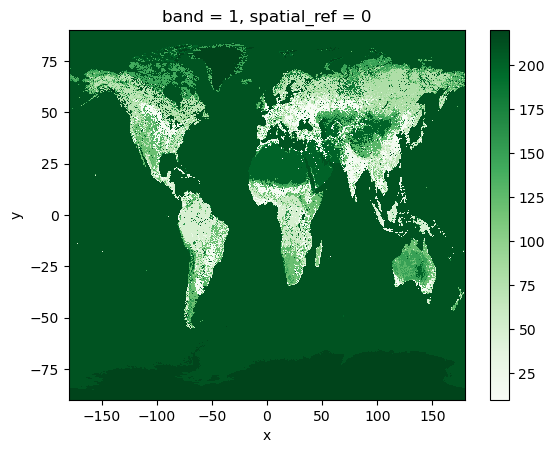

In [23]:
LCHansen20002.plot(cmap="Greens")

In [24]:
LCHansen20002forest = (LCHansen20002 >= 50) & (LCHansen20002 <= 90)

In [25]:
LCHansen20002

<xarray.DataArray (band: 1, y: 3600, x: 7200)> Size: 104MB
array([[[210., 210., ..., 210., 210.],
        [210., 210., ..., 210., 210.],
        ...,
        [220., 220., ..., 220., 220.],
        [220., 220., ..., 220., 220.]]], shape=(1, 3600, 7200), dtype=float32)
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 29kB 89.97 89.92 89.88 ... -89.88 -89.93 -89.98
  * x            (x) float64 58kB -180.0 -179.9 -179.9 ... 179.9 179.9 180.0
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [26]:
LCHansen20002forest

<xarray.DataArray (band: 1, y: 3600, x: 7200)> Size: 26MB
array([[[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]]],
      shape=(1, 3600, 7200))
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 29kB 89.97 89.92 89.88 ... -89.88 -89.93 -89.98
  * x            (x) float64 58kB -180.0 -179.9 -179.9 ... 179.9 179.9 180.0
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

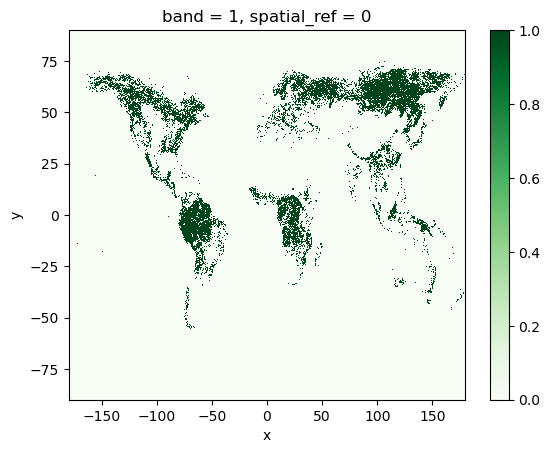

In [27]:
LCHansen20002forest.plot(cmap="Greens")

## Select areas with snow and ice Hansen

In [28]:
maskLCHansen20002snow = (LCHansen20002 == 210)

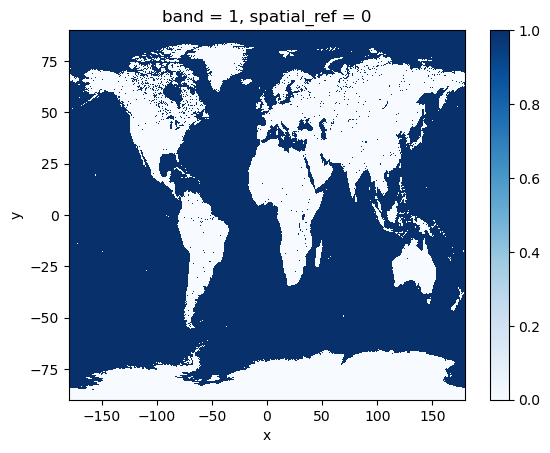

In [29]:
maskLCHansen20002snow.plot(cmap='Blues')

## GLC Select areas with forest

In [30]:
maskGLC_FCS302000E25N70band1 = (GLC_FCS302000E25N70band1 >= 51) & (GLC_FCS302000E25N70band1 <= 92)

In [31]:
maskGLC_FCS302000W110N60band1 = (GLC_FCS302000W110N60band1 >= 51) & (GLC_FCS302000W110N60band1 <= 92)

## GLC Select areas with snow and ice

In [32]:
GLC_FCS302000E90N25band1

<xarray.DataArray (y: 18554, x: 18554)> Size: 344MB
[344250916 values with dtype=uint8]
Coordinates:
  * y            (y) float64 148kB 25.0 25.0 25.0 25.0 ... 20.0 20.0 20.0 20.0
  * x            (x) float64 148kB 90.0 90.0 90.0 90.0 ... 95.0 95.0 95.0 95.0
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [33]:
GLC_FCS302000E5N50band1

<xarray.DataArray (y: 18554, x: 18554)> Size: 344MB
[344250916 values with dtype=uint8]
Coordinates:
  * y            (y) float64 148kB 50.0 50.0 50.0 50.0 ... 45.0 45.0 45.0 45.0
  * x            (x) float64 148kB 5.0 5.0 5.001 5.001 ... 9.999 10.0 10.0 10.0
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [257]:
maskGLC_FCS302000E85N30band1 = (GLC_FCS302000E85N30band1 == 220)| (GLC_FCS302000E85N30band1 == 0)

In [258]:
maskGLC_FCS302000E5N50band1 = (GLC_FCS302000E5N50band1 == 220)| (GLC_FCS302000E5N50band1 == 0)

In [219]:
 #  | (GLC_FCS302000E5N50band1 == 0)(GLC_FCS302000E90N25band1 == 0) (GLC_FCS302000E90N25band1 == 210) | (GLC_FCS302000E90N25band1 == 210) | | (GLC_FCS302000E5N50band1 == ) | (GLC_FCS302000E5N50band1 == ) | (GLC_FCS302000E5N50band1 == ) | (GLC_FCS302000E5N50band1 == ) | (GLC_FCS302000E5N50band1 == ) | (GLC_FCS302000E5N50band1 == ) | (GLC_FCS302000E5N50band1 == )

In [259]:
maskGLC_FCS30200010E80Sband1 = (GLC_FCS30200010E80Sband1 == 220) | (GLC_FCS30200010E80Sband1 == 0)

In [195]:
 # | (GLC_FCS30200010E80Sband1 == 0) | (GLC_FCS30200010E80Sband1 == 220) | (GLC_FCS30200010E80Sband1 == 0) | (GLC_FCS30200010E80Sband1 == 202) | (GLC_FCS30200010E80Sband1 == 201) | (GLC_FCS30200010E80Sband1 == 200) | (GLC_FCS30200010E80Sband1 == 184) | (GLC_FCS30200010E80Sband1 == 183)

  grassland, 130
  sparse vegetation, 150
  flooded flat, 183
  saline, 184
  Impervious_surfaces, 190
  Bare_areas 200
  'Consolidated_bare_areas', 201
  Unconsolidated_bare_areas', 202
  'Water_body', 210
  'Permanent_ice_and_snow', 220
  'Filled_value' 0

# Mask Hansen E25 N70

In [39]:
bounds = GLC_FCS302000E25N70band1.rio.bounds()
print(bounds)

(25.0, 64.99979746553392, 30.000202534466077, 70.0)


Text(0.5, 1.0, 'Urho Kekkonen National Park LC Hansen 2000 E0 N10')

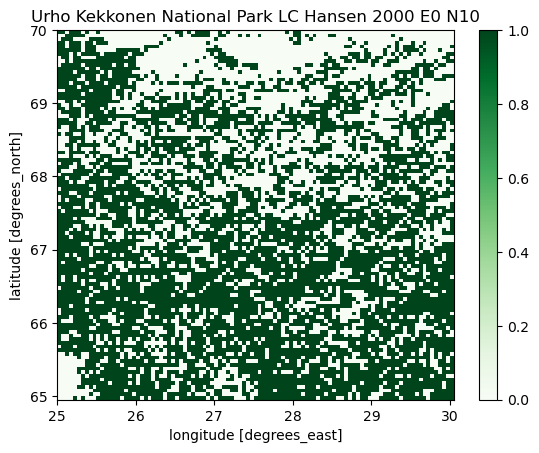

In [40]:
maskLC_HansenE25N70 = LCHansen20002forest.rio.clip_box(
    minx=25.0,
    miny=64.99979746553392,
    maxx=30.000202534466077,
    maxy=70.0
)
maskLC_HansenE25N70.plot(cmap='Greens')
pyplot.title("Urho Kekkonen National Park LC Hansen 2000 E0 N10")

# Resample GLC E25 N70

In [41]:
maskGLC_FCS302000E25N70band1int = maskGLC_FCS302000E25N70band1.astype(int)

# Resample with interp

In [42]:
maskGLC_FCS302000E25N70band1int_interp = maskGLC_FCS302000E25N70band1int.interp(x = maskLC_HansenE25N70['x'], y = maskLC_HansenE25N70['y'], method='nearest')

In [43]:
maskGLC_FCS302000E25N70band1int_interp

<xarray.DataArray (y: 101, x: 101)> Size: 82kB
array([[ 0.,  0.,  0., ...,  0.,  0., nan],
       [ 1.,  0.,  1., ...,  0.,  0., nan],
       [ 0.,  1.,  1., ...,  0.,  0., nan],
       ...,
       [ 0.,  0.,  0., ...,  1.,  1., nan],
       [ 0.,  0.,  0., ...,  1.,  1., nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(101, 101))
Coordinates:
  * y            (y) float64 808B 69.97 69.92 69.88 69.82 ... 65.07 65.02 64.97
  * x            (x) float64 808B 25.03 25.08 25.13 25.18 ... 29.93 29.98 30.03
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

Text(0.5, 1.0, 'Urho Kekkonen National Park LC Hansen 2000 E0 N10')

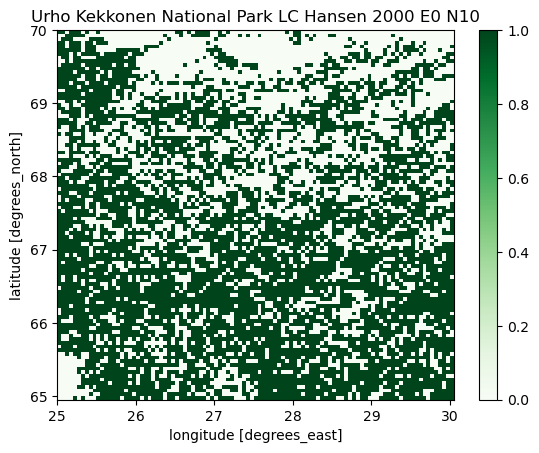

In [44]:
maskLC_HansenE25N70 = LCHansen20002forest.rio.clip_box(
    minx=25.0,
    miny=64.99979746553392,
    maxx=30.000202534466077,
    maxy=70.0
)
maskLC_HansenE25N70.plot(cmap='Greens')
pyplot.title("Urho Kekkonen National Park LC Hansen 2000 E0 N10")

Text(0.5, 1.0, 'Urho Kekkonen National Park GLC FCS30 2000 E25 N70')

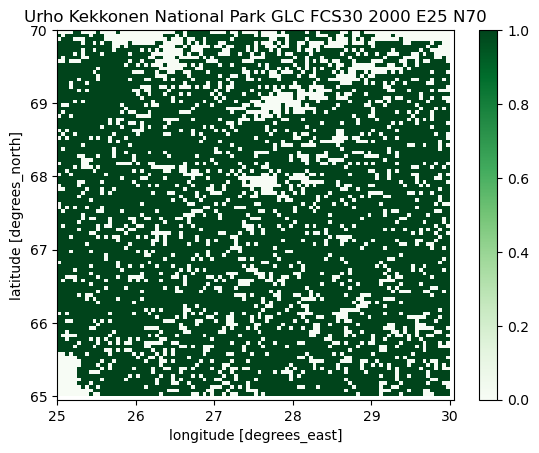

In [45]:
maskGLC_FCS302000E25N70band1int_interp.plot(cmap="Greens")
pyplot.title("Urho Kekkonen National Park GLC FCS30 2000 E25 N70")

# Compare two plots

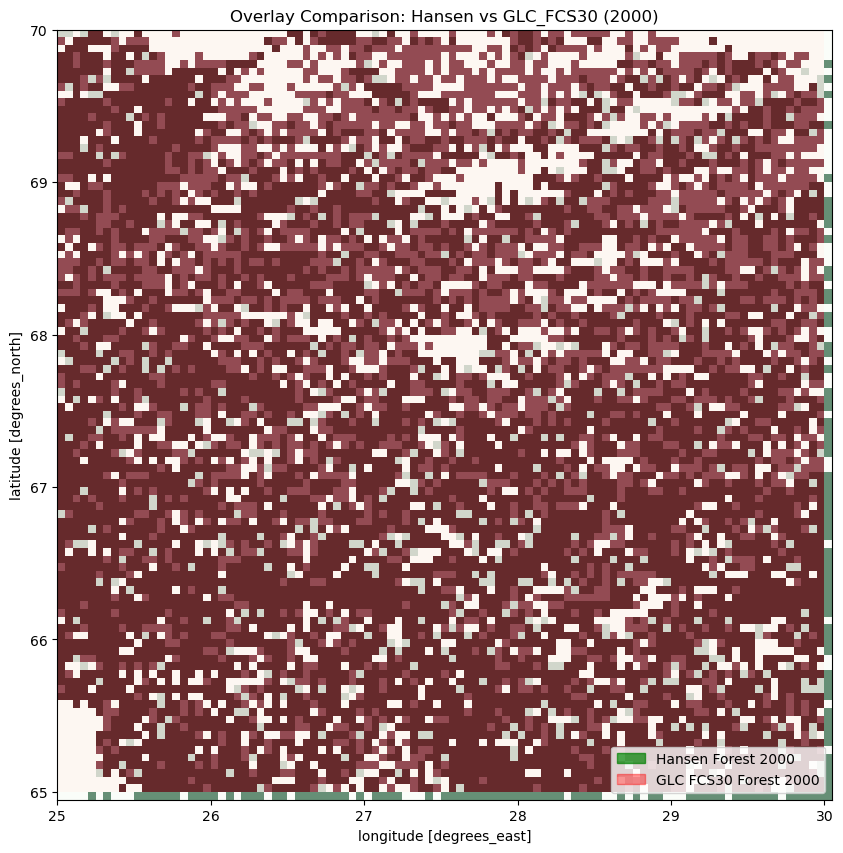

In [46]:
fig, ax = pyplot.subplots(figsize=(10, 10))

# First dataset
maskLC_HansenE25N70.plot(
    ax=ax,
    cmap="Greens",
    alpha=0.6,
    add_colorbar=False
)

# Second dataset overlay
maskGLC_FCS302000E25N70band1int_interp.plot(
    ax=ax,
    cmap="Reds",
    alpha=0.7,
    add_colorbar=False
)

# Legend patches
green_patch = mpatches.Patch(
    color="green",
    alpha=0.7,
    label="Hansen Forest 2000"
)

red_patch = mpatches.Patch(
    color="red",
    alpha=0.4,
    label="GLC FCS30 Forest 2000"
)

# Add legend
ax.legend(
    handles=[green_patch, red_patch],
    loc="lower right",
    frameon=True
)

ax.set_title("Overlay Comparison: Hansen vs GLC_FCS30 (2000)")

pyplot.show()

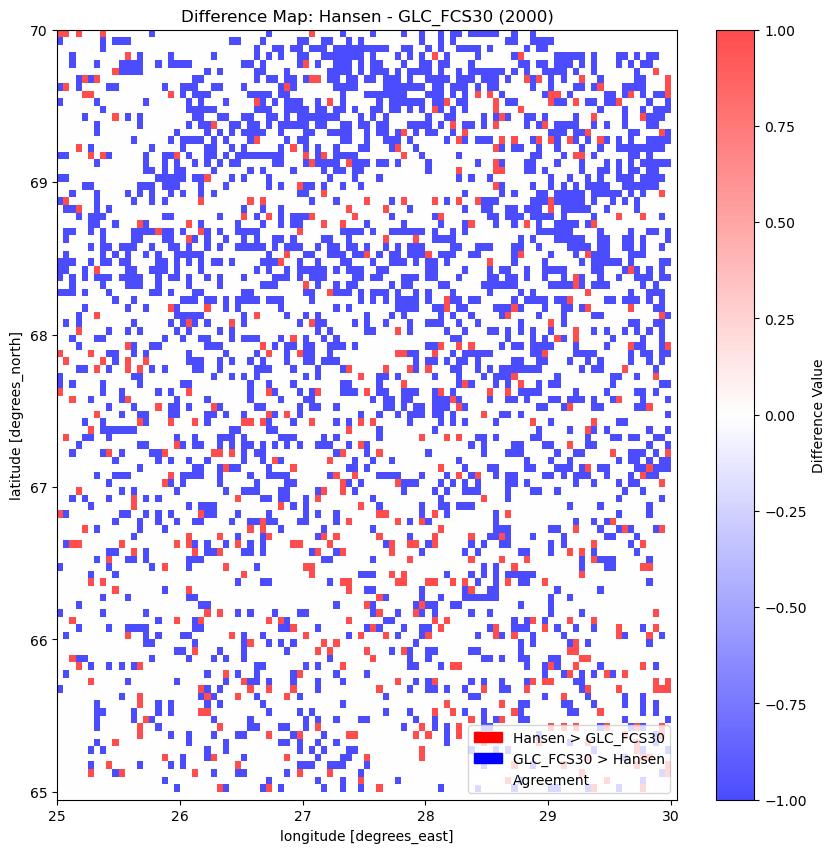

In [47]:
# Align grids
mask_aligned = (
    maskGLC_FCS302000E25N70band1int_interp
    .rio.reproject_match(maskLC_HansenE25N70)
)

# Difference map
difference = maskLC_HansenE25N70 - mask_aligned

# Symmetric color scaling
vmax = np.nanmax(np.abs(difference))

fig, ax = pyplot.subplots(figsize=(10, 10))

# Plot raster
im = difference.plot(
    ax=ax,
    cmap="bwr",
    alpha=0.7,
    vmin=-vmax,
    vmax=vmax,
    cbar_kwargs={"label": "Difference Value"}
)

# Custom legend
red_patch = mpatches.Patch(color="red", label="Hansen > GLC_FCS30")
blue_patch = mpatches.Patch(color="blue", label="GLC_FCS30 > Hansen")
white_patch = mpatches.Patch(color="white", label="Agreement")

ax.legend(
    handles=[red_patch, blue_patch, white_patch],
    loc="lower right",
    frameon=True
)

ax.set_title("Difference Map: Hansen - GLC_FCS30 (2000)")

pyplot.show()

# Mask Hansen W110 N60

In [48]:
bounds = GLC_FCS302000W110N60band1.rio.bounds()
print(bounds)

(-110.0, 54.999797465533916, -104.99979746553392, 60.0)


Text(0.5, 1.0, 'Wood Buffalo National Park LC Hansen 2000 W110 N60')

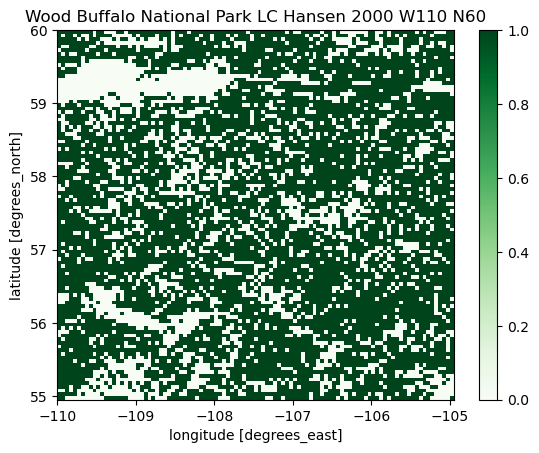

In [49]:
maskLC_HansenW110N60 = LCHansen20002forest.rio.clip_box(
    minx=-110.0,
    miny=54.999797465533916,
    maxx=-104.99979746553392,
    maxy=60.0
)
maskLC_HansenW110N60.plot(cmap='Greens')
pyplot.title("Wood Buffalo National Park LC Hansen 2000 W110 N60")

# Resample GLC W110 N60

In [50]:
maskGLC_FCS302000W110N60band1int = maskGLC_FCS302000W110N60band1.astype(int)

# Resample with interp

In [51]:
maskGLC_FCS302000W110N60band1int_interp = maskGLC_FCS302000W110N60band1int.interp(x = maskLC_HansenW110N60['x'], y = maskLC_HansenW110N60['y'], method='nearest')

Text(0.5, 1.0, 'Wood Buffalo National Park LC Hansen 2000 W110 N60')

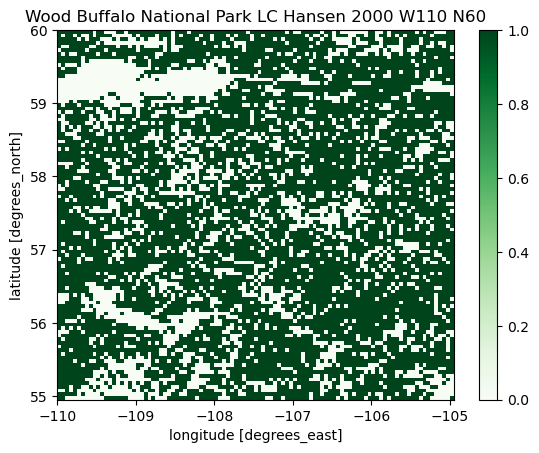

In [52]:
maskLC_HansenW110N60 = LCHansen20002forest.rio.clip_box(
    minx=-110.0,
    miny=54.999797465533916,
    maxx=-104.99979746553392,
    maxy=60.0
)
maskLC_HansenW110N60.plot(cmap='Greens')
pyplot.title("Wood Buffalo National Park LC Hansen 2000 W110 N60")

Text(0.5, 1.0, 'Wood Buffalo National Park GLC FCS30 2000 W110 N60')

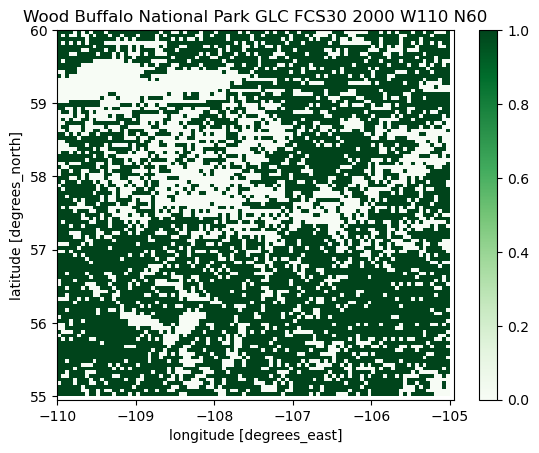

In [53]:
maskGLC_FCS302000W110N60band1int_interp.plot(cmap="Greens")
pyplot.title("Wood Buffalo National Park GLC FCS30 2000 W110 N60")

# Compare the the plots

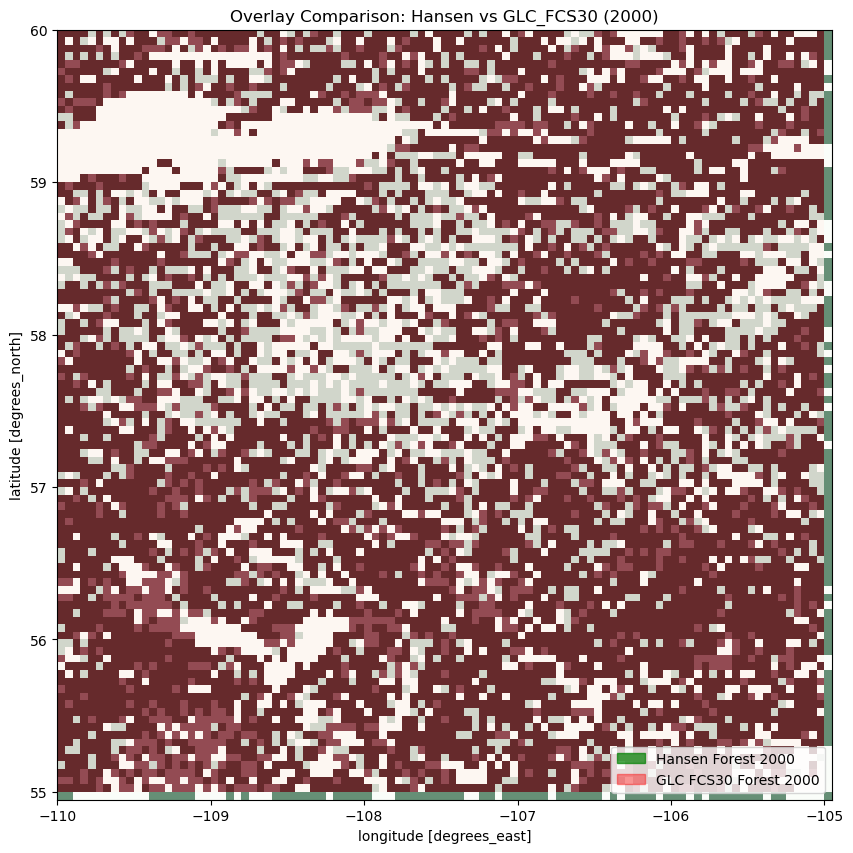

In [54]:
fig, ax = pyplot.subplots(figsize=(10, 10))

# First dataset
maskLC_HansenW110N60.plot(
    ax=ax,
    cmap="Greens",
    alpha=0.6,
    add_colorbar=False
)

# Second dataset overlay
maskGLC_FCS302000W110N60band1int_interp.plot(
    ax=ax,
    cmap="Reds",
    alpha=0.7,
    add_colorbar=False
)

# Legend patches
green_patch = mpatches.Patch(
    color="green",
    alpha=0.7,
    label="Hansen Forest 2000"
)

red_patch = mpatches.Patch(
    color="red",
    alpha=0.4,
    label="GLC FCS30 Forest 2000"
)

# Add legend
ax.legend(
    handles=[green_patch, red_patch],
    loc="lower right",
    frameon=True
)

ax.set_title("Overlay Comparison: Hansen vs GLC_FCS30 (2000)")

pyplot.show()

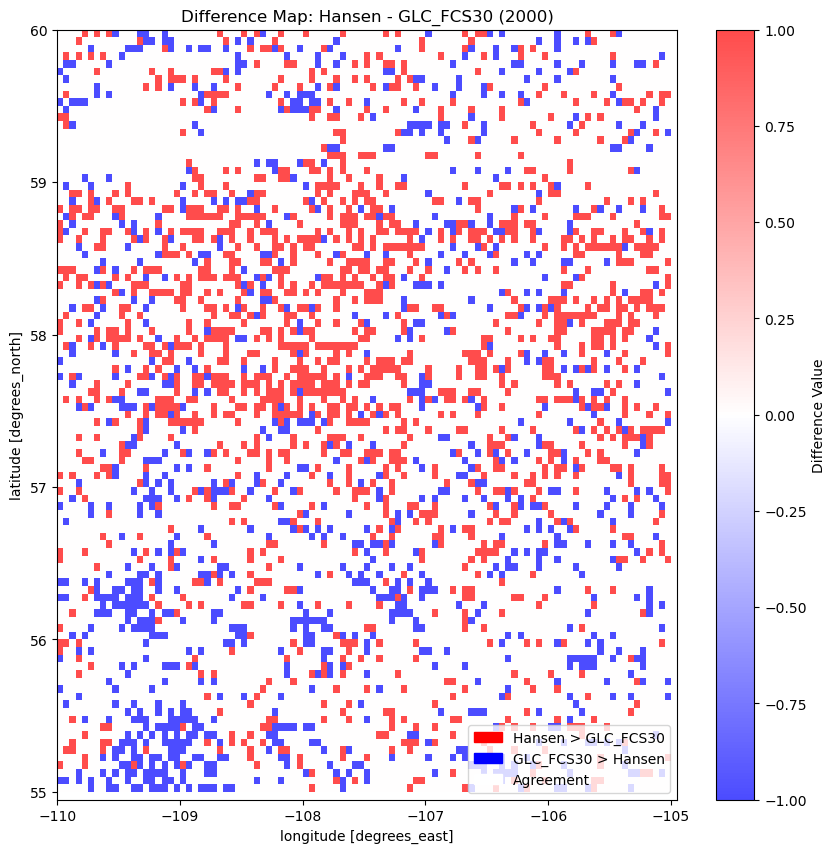

In [55]:
# Align grids
mask_aligned = (
    maskGLC_FCS302000W110N60band1int_interp
    .rio.reproject_match(maskLC_HansenW110N60)
)

# Difference map
difference = maskLC_HansenW110N60 - mask_aligned

# Symmetric color scaling
vmax = np.nanmax(np.abs(difference))

fig, ax = pyplot.subplots(figsize=(10, 10))

# Plot raster
im = difference.plot(
    ax=ax,
    cmap="bwr",
    alpha=0.7,
    vmin=-vmax,
    vmax=vmax,
    cbar_kwargs={"label": "Difference Value"}
)

# Custom legend
red_patch = mpatches.Patch(color="red", label="Hansen > GLC_FCS30")
blue_patch = mpatches.Patch(color="blue", label="GLC_FCS30 > Hansen")
white_patch = mpatches.Patch(color="white", label="Agreement")

ax.legend(
    handles=[red_patch, blue_patch, white_patch],
    loc="lower right",
    frameon=True
)

ax.set_title("Difference Map: Hansen - GLC_FCS30 (2000)")

pyplot.show()

# Mask E85 N30

In [260]:
bounds = GLC_FCS302000E85N30band1.rio.bounds()
print(bounds)

(85.0, 24.999797465533923, 90.00020253446608, 30.0)


Text(0.5, 1.0, 'Mount Everest LC Hansen 2000 E85 N30')

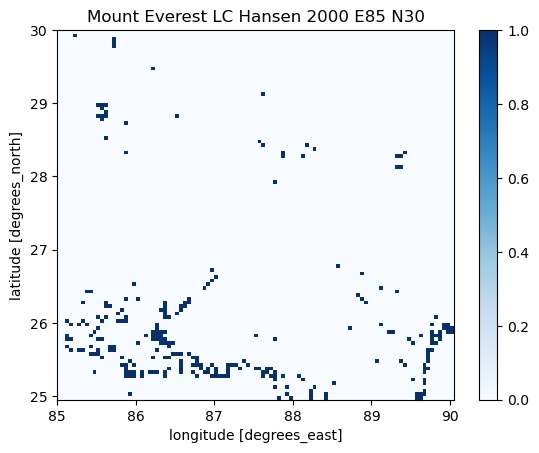

In [261]:
maskLC_HansenE85N30 = maskLCHansen20002snow.rio.clip_box(
    minx=85.0,
    miny=24.999797465533923,
    maxx=90.00020253446608,
    maxy=30.0
)
maskLC_HansenE85N30.plot(cmap='Blues')
pyplot.title("Mount Everest LC Hansen 2000 E85 N30")

# Resample GLC E85 N30

In [262]:
maskGLC_FCS302000E85N30band1

<xarray.DataArray (y: 18554, x: 18554)> Size: 344MB
array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False,  True],
       [False, False, False, ..., False, False,  True],
       [ True,  True,  True, ...,  True,  True,  True]],
      shape=(18554, 18554))
Coordinates:
  * y            (y) float64 148kB 30.0 30.0 30.0 30.0 ... 25.0 25.0 25.0 25.0
  * x            (x) float64 148kB 85.0 85.0 85.0 85.0 ... 90.0 90.0 90.0 90.0
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [263]:
maskGLC_FCS302000E85N30band1int = maskGLC_FCS302000E85N30band1.astype(int)

In [264]:
maskGLC_FCS302000E85N30band1int

<xarray.DataArray (y: 18554, x: 18554)> Size: 3GB
array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 1],
       [0, 0, 0, ..., 0, 0, 1],
       [1, 1, 1, ..., 1, 1, 1]], shape=(18554, 18554))
Coordinates:
  * y            (y) float64 148kB 30.0 30.0 30.0 30.0 ... 25.0 25.0 25.0 25.0
  * x            (x) float64 148kB 85.0 85.0 85.0 85.0 ... 90.0 90.0 90.0 90.0
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

# Resample with interp

In [267]:
croppedLCHansen2000E85N30 = LCHansen20002.rio.clip_box(
    minx=85.0,
    miny=24.999797465533923,
    maxx=90.00020253446608,
    maxy=30.0
)

In [268]:
maskGLC_FCS302000E85N30band1int_interp = maskGLC_FCS302000E85N30band1int.interp(x = croppedLCHansen2000E85N30['x'], y = croppedLCHansen2000E85N30['y'], method='nearest')

# Plot E85 N30

Text(0.5, 1.0, 'Mount Everest LC Hansen 2000 E85 N30')

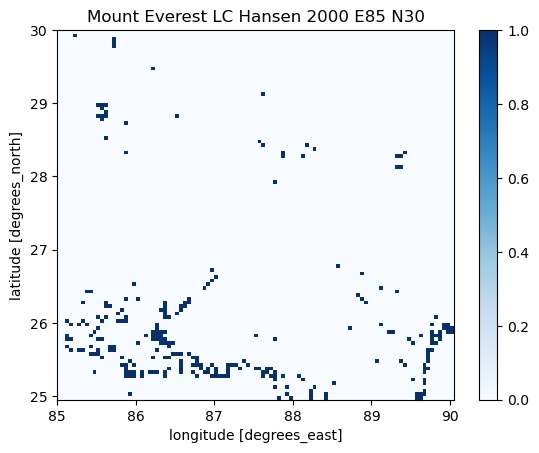

In [269]:
maskLC_HansenE85N30 = maskLCHansen20002snow.rio.clip_box(
    minx=85.0,
    miny=24.999797465533923,
    maxx=90.00020253446608,
    maxy=30.0
)
maskLC_HansenE85N30.plot(cmap='Blues')
pyplot.title("Mount Everest LC Hansen 2000 E85 N30")

Text(0.5, 1.0, 'Mount Everest GLC FCS30 2000 E85 N30')

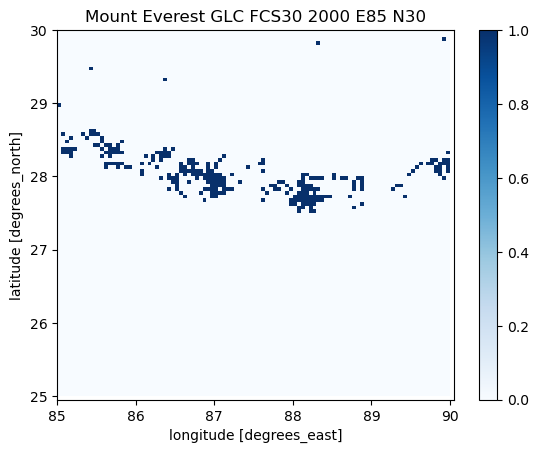

In [270]:
maskGLC_FCS302000E85N30band1int_interp.plot(cmap="Blues")
pyplot.title("Mount Everest GLC FCS30 2000 E85 N30")

# Compare the plots

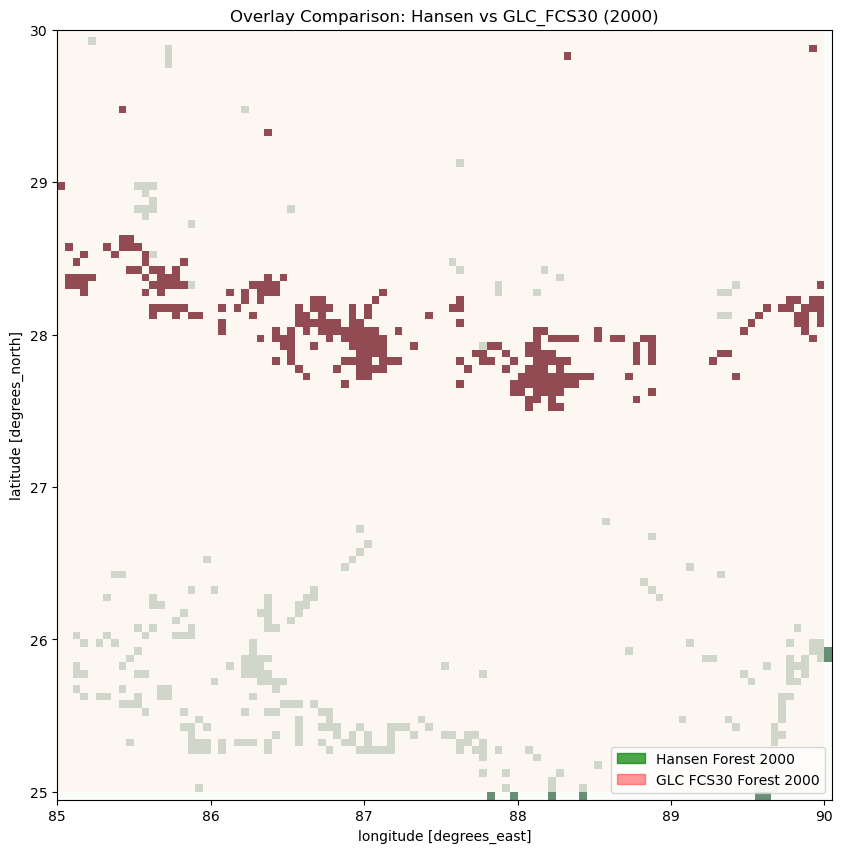

In [271]:
fig, ax = pyplot.subplots(figsize=(10, 10))

# First dataset
maskLC_HansenE85N30.plot(
    ax=ax,
    cmap="Greens",
    alpha=0.6,
    add_colorbar=False
)

# Second dataset overlay
maskGLC_FCS302000E85N30band1int_interp.plot(
    ax=ax,
    cmap="Reds",
    alpha=0.7,
    add_colorbar=False
)

# Legend patches
green_patch = mpatches.Patch(
    color="green",
    alpha=0.7,
    label="Hansen Forest 2000"
)

red_patch = mpatches.Patch(
    color="red",
    alpha=0.4,
    label="GLC FCS30 Forest 2000"
)

# Add legend
ax.legend(
    handles=[green_patch, red_patch],
    loc="lower right",
    frameon=True
)

ax.set_title("Overlay Comparison: Hansen vs GLC_FCS30 (2000)")

pyplot.show()

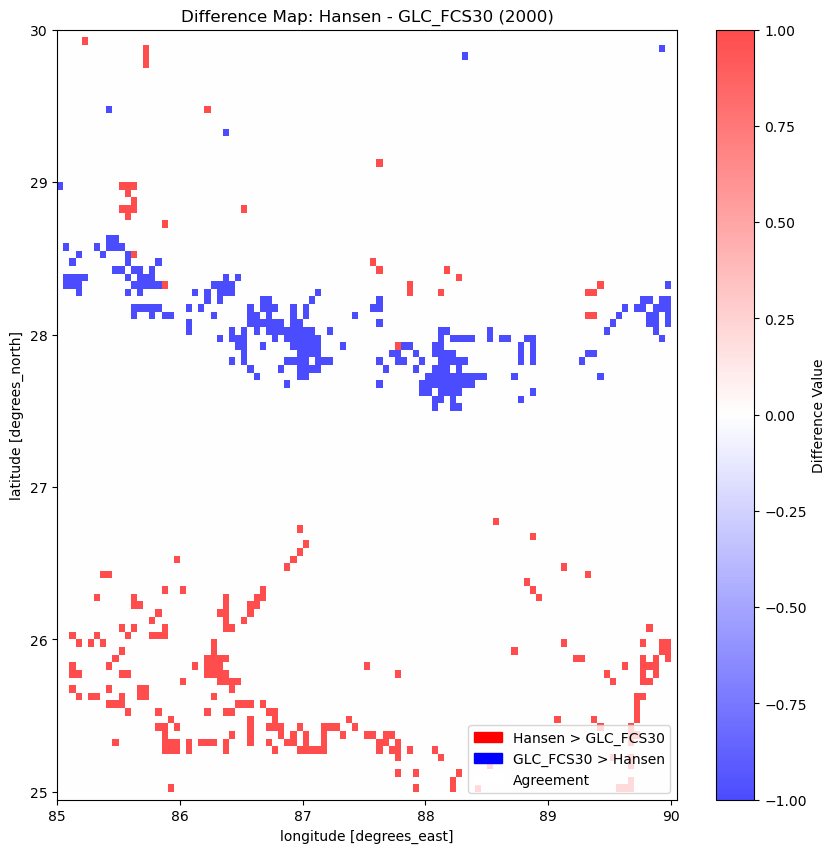

In [272]:
# Align grids
mask_aligned = (
    maskGLC_FCS302000E85N30band1int_interp
    .rio.reproject_match(maskLC_HansenE85N30)
)

# Difference map
difference = maskLC_HansenE85N30 - mask_aligned

# Symmetric color scaling
vmax = np.nanmax(np.abs(difference))

fig, ax = pyplot.subplots(figsize=(10, 10))

# Plot raster
im = difference.plot(
    ax=ax,
    cmap="bwr",
    alpha=0.7,
    vmin=-vmax,
    vmax=vmax,
    cbar_kwargs={"label": "Difference Value"}
)

# Custom legend
red_patch = mpatches.Patch(color="red", label="Hansen > GLC_FCS30")
blue_patch = mpatches.Patch(color="blue", label="GLC_FCS30 > Hansen")
white_patch = mpatches.Patch(color="white", label="Agreement")

ax.legend(
    handles=[red_patch, blue_patch, white_patch],
    loc="lower right",
    frameon=True
)

ax.set_title("Difference Map: Hansen - GLC_FCS30 (2000)")

pyplot.show()

# Mask E5N 50

In [273]:
bounds = GLC_FCS302000E5N50band1.rio.bounds()
print(bounds)

(5.0, 44.999797465533916, 10.00020253446608, 50.0)


Text(0.5, 1.0, 'Mont Blanc LC Hansen 2000 E5 N50')

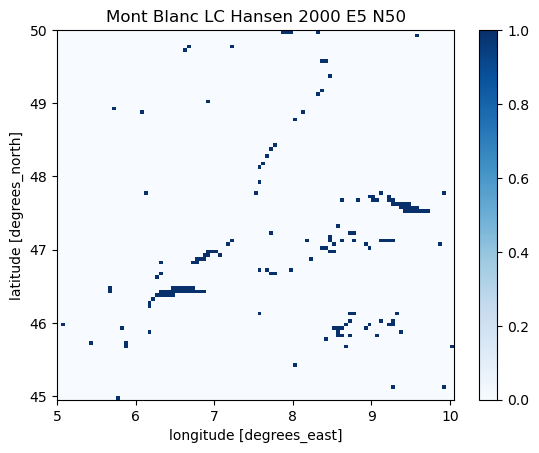

In [274]:
maskLC_HansenE5N50 = maskLCHansen20002snow.rio.clip_box(
    minx=5.0,
    miny=44.999797465533916,
    maxx=10.00020253446608,
    maxy=50.0
)
maskLC_HansenE5N50.plot(cmap='Blues')
pyplot.title("Mont Blanc LC Hansen 2000 E5 N50")

In [275]:
maskGLC_FCS302000E5N50band1int = maskGLC_FCS302000E5N50band1.astype(int)

# Resample with interp

In [276]:
croppedLCHansen2000E5N50 = maskLCHansen20002snow.rio.clip_box(
    minx=5.0,
    miny=44.999797465533916,
    maxx=10.00020253446608,
    maxy=50.0
)

In [277]:
maskGLC_FCS302000E5N505band1int_interp = maskGLC_FCS302000E5N50band1int.interp(x = croppedLCHansen2000E5N50['x'], y = croppedLCHansen2000E5N50['y'], method='nearest')

Text(0.5, 1.0, 'Mont Blanc LC Hansen 2000 E5 N50')

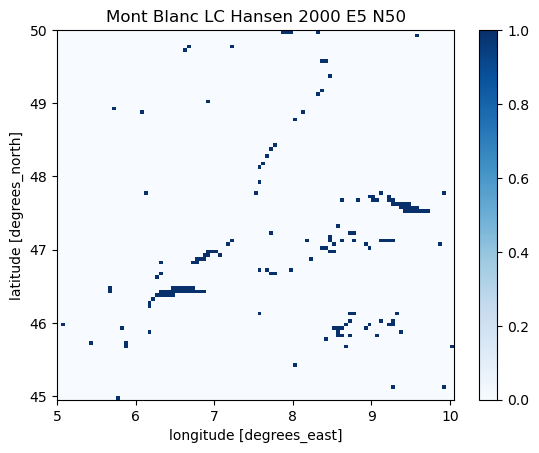

In [278]:
croppedLCHansen2000E5N50.plot(cmap='Blues')
pyplot.title("Mont Blanc LC Hansen 2000 E5 N50")

Text(0.5, 1.0, 'Mont Blanc GLC FCS30 2000 E5 N50')

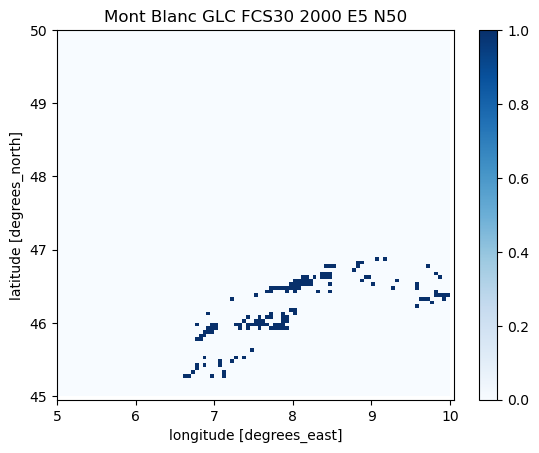

In [279]:
maskGLC_FCS302000E5N505band1int_interp.plot(cmap="Blues")
pyplot.title("Mont Blanc GLC FCS30 2000 E5 N50")

# Compare the plots

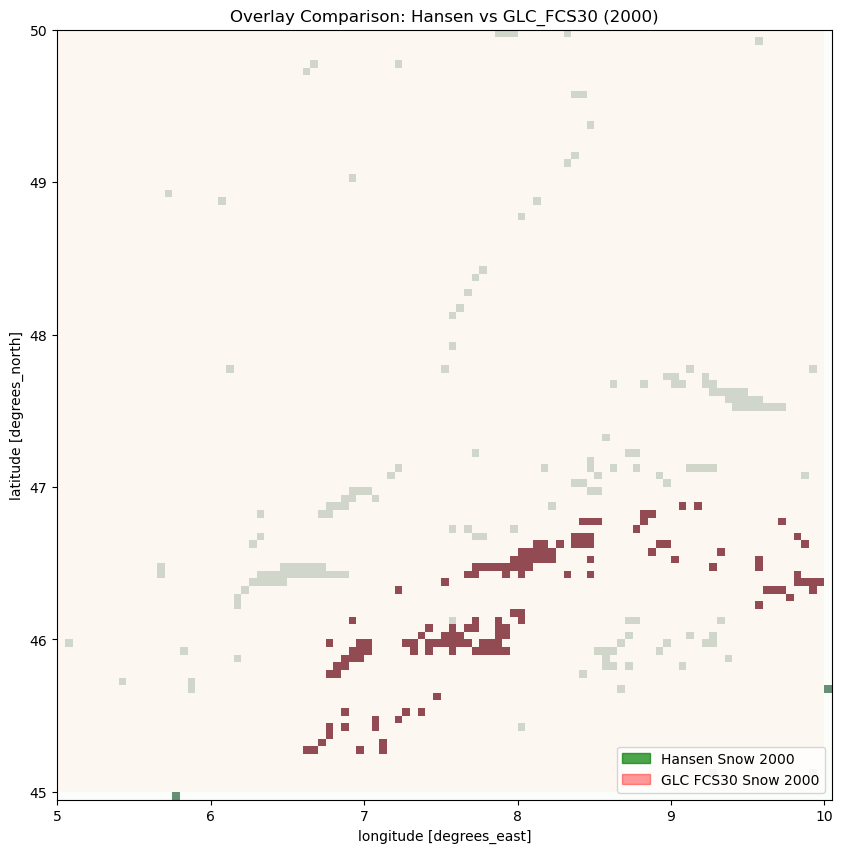

In [280]:
fig, ax = pyplot.subplots(figsize=(10, 10))

# First dataset
maskLC_HansenE5N50.plot(
    ax=ax,
    cmap="Greens",
    alpha=0.6,
    add_colorbar=False
)

# Second dataset overlay
maskGLC_FCS302000E5N505band1int_interp.plot(
    ax=ax,
    cmap="Reds",
    alpha=0.7,
    add_colorbar=False
)

# Legend patches
green_patch = mpatches.Patch(
    color="green",
    alpha=0.7,
    label="Hansen Snow 2000"
)

red_patch = mpatches.Patch(
    color="red",
    alpha=0.4,
    label="GLC FCS30 Snow 2000"
)

# Add legend
ax.legend(
    handles=[green_patch, red_patch],
    loc="lower right",
    frameon=True
)

ax.set_title("Overlay Comparison: Hansen vs GLC_FCS30 (2000)")

pyplot.show()

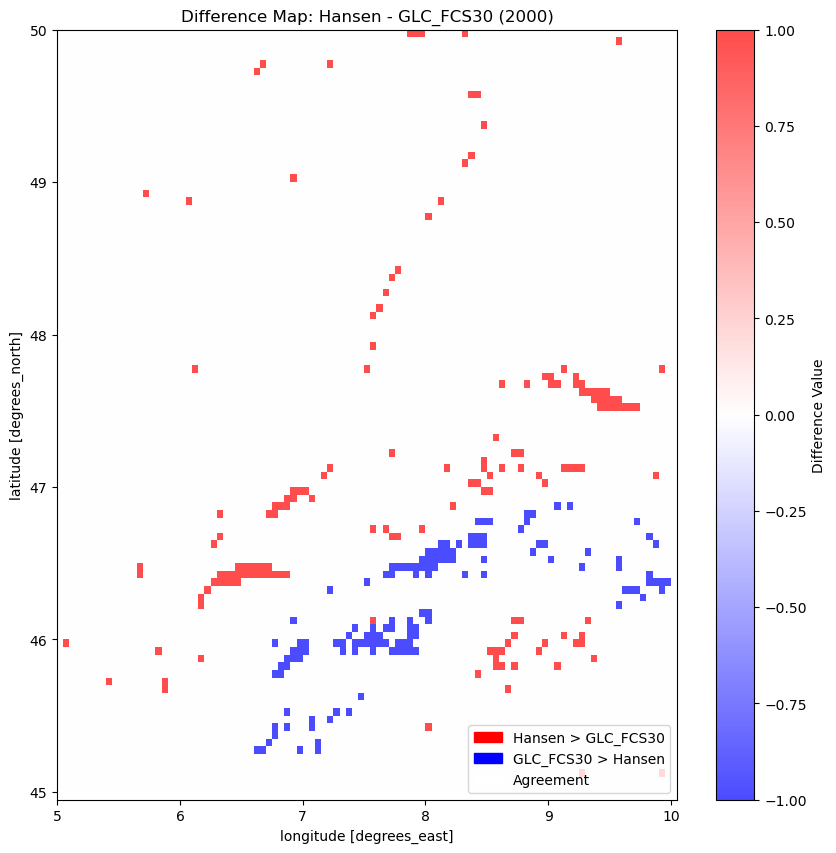

In [281]:
# Align grids
mask_aligned = (
    maskGLC_FCS302000E5N505band1int_interp
    .rio.reproject_match(maskLC_HansenE5N50)
)

# Difference map
difference = maskLC_HansenE5N50 - mask_aligned

# Symmetric color scaling
vmax = np.nanmax(np.abs(difference))

fig, ax = pyplot.subplots(figsize=(10, 10))

# Plot raster
im = difference.plot(
    ax=ax,
    cmap="bwr",
    alpha=0.7,
    vmin=-vmax,
    vmax=vmax,
    cbar_kwargs={"label": "Difference Value"}
)

# Custom legend
red_patch = mpatches.Patch(color="red", label="Hansen > GLC_FCS30")
blue_patch = mpatches.Patch(color="blue", label="GLC_FCS30 > Hansen")
white_patch = mpatches.Patch(color="white", label="Agreement")

ax.legend(
    handles=[red_patch, blue_patch, white_patch],
    loc="lower right",
    frameon=True
)

ax.set_title("Difference Map: Hansen - GLC_FCS30 (2000)")

pyplot.show()

# Mask Hansen E10 S80

In [282]:
bounds = GLC_FCS30200010E80Sband1.rio.bounds()
print(bounds)

(10.0, 74.99979746553392, 15.000202534466082, 80.0)


Text(0.5, 1.0, 'Antarctica LC Hansen 2000 E10 S80')

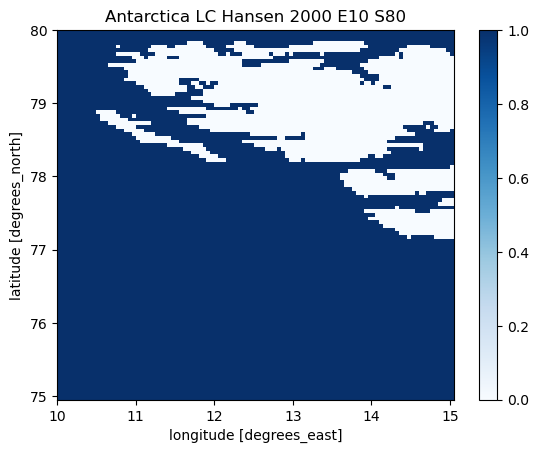

In [283]:
maskLC_HansenE10N80 = maskLCHansen20002snow.rio.clip_box(
    minx=10.0,
    miny=74.99979746553392,
    maxx=15.000202534466082,
    maxy=80.0
)
maskLC_HansenE10N80.plot(cmap='Blues')
pyplot.title("Antarctica LC Hansen 2000 E10 S80")

# Resample E10 S80

In [284]:
maskGLC_FCS30200010E80Sband1int = maskGLC_FCS30200010E80Sband1.astype(int)

In [285]:
maskGLC_FCS30200010E80Sband_interp = maskGLC_FCS30200010E80Sband1int.interp(x = maskLC_HansenE10N80['x'], y = maskLC_HansenE10N80['y'], method='nearest')

# Plot E10 S80

Text(0.5, 1.0, 'Antarcica LC Hansen 2000 E10 N80')

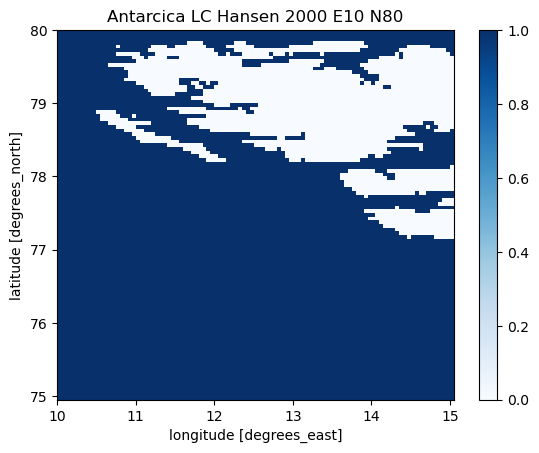

In [286]:
maskLC_HansenE10N80.plot(cmap='Blues')
pyplot.title("Antarcica LC Hansen 2000 E10 N80")

Text(0.5, 1.0, 'Antarcica LC GLC FCS30 2000 E10 N80')

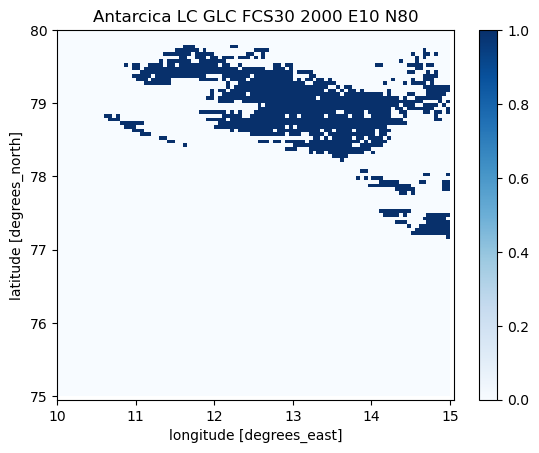

In [287]:
maskGLC_FCS30200010E80Sband_interp.plot(cmap="Blues")
pyplot.title("Antarcica LC GLC FCS30 2000 E10 N80")

# Compare the plots

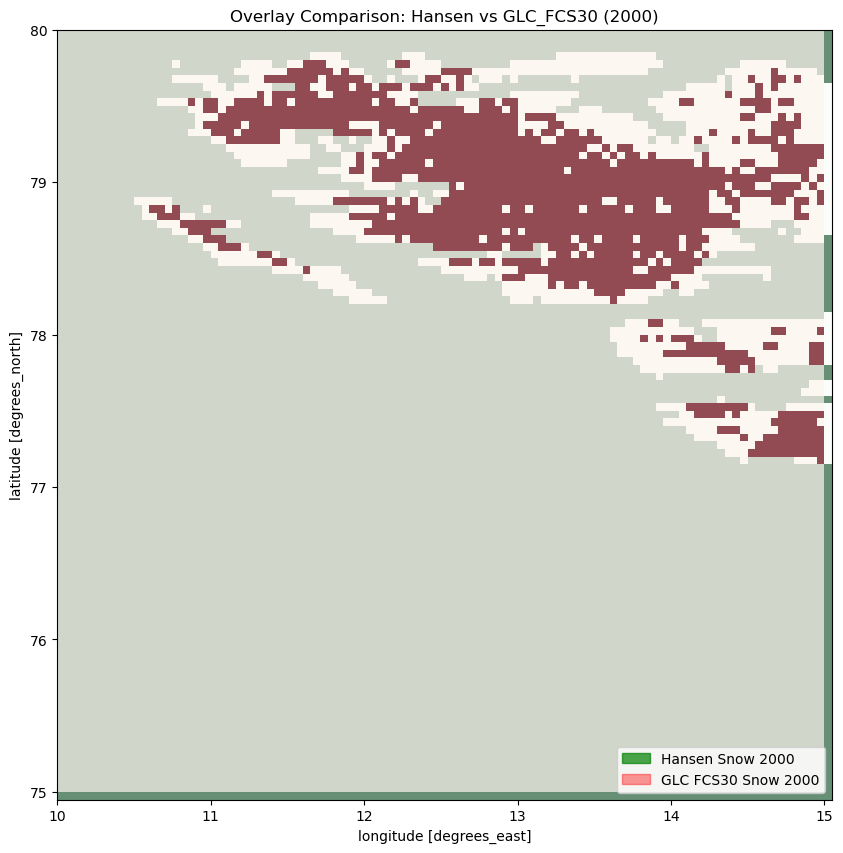

In [288]:
fig, ax = pyplot.subplots(figsize=(10, 10))

# First dataset
maskLC_HansenE10N80.plot(
    ax=ax,
    cmap="Greens",
    alpha=0.6,
    add_colorbar=False
)

# Second dataset overlay
maskGLC_FCS30200010E80Sband_interp.plot(
    ax=ax,
    cmap="Reds",
    alpha=0.7,
    add_colorbar=False
)

# Legend patches
green_patch = mpatches.Patch(
    color="green",
    alpha=0.7,
    label="Hansen Snow 2000"
)

red_patch = mpatches.Patch(
    color="red",
    alpha=0.4,
    label="GLC FCS30 Snow 2000"
)

# Add legend
ax.legend(
    handles=[green_patch, red_patch],
    loc="lower right",
    frameon=True
)

ax.set_title("Overlay Comparison: Hansen vs GLC_FCS30 (2000)")

pyplot.show()

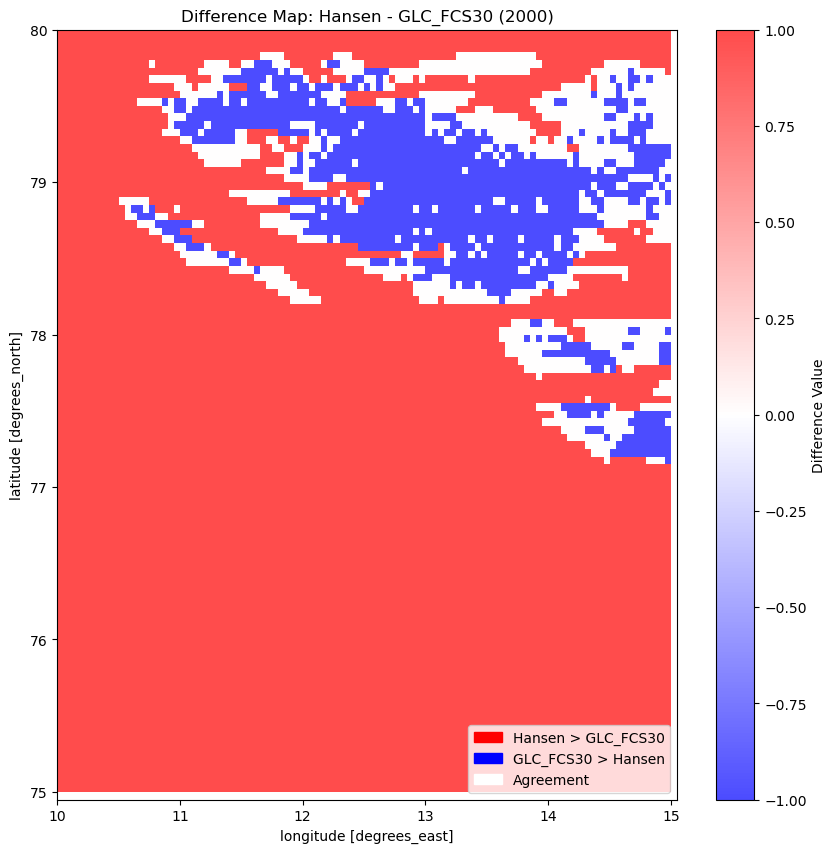

In [289]:
# Align grids
mask_aligned = (
    maskGLC_FCS30200010E80Sband_interp
    .rio.reproject_match(maskLC_HansenE10N80)
)

# Difference map
difference = maskLC_HansenE10N80 - mask_aligned

# Symmetric color scaling
vmax = np.nanmax(np.abs(difference))

fig, ax = pyplot.subplots(figsize=(10, 10))

# Plot raster
im = difference.plot(
    ax=ax,
    cmap="bwr",
    alpha=0.7,
    vmin=-vmax,
    vmax=vmax,
    cbar_kwargs={"label": "Difference Value"}
)

# Custom legend
red_patch = mpatches.Patch(color="red", label="Hansen > GLC_FCS30")
blue_patch = mpatches.Patch(color="blue", label="GLC_FCS30 > Hansen")
white_patch = mpatches.Patch(color="white", label="Agreement")

ax.legend(
    handles=[red_patch, blue_patch, white_patch],
    loc="lower right",
    frameon=True
)

ax.set_title("Difference Map: Hansen - GLC_FCS30 (2000)")

pyplot.show()

# Compare the LC maps

## E25N70

In [84]:
maskGLC_FCS302000E25N70band1int_interparr = maskGLC_FCS302000E25N70band1int_interp.values

In [85]:
maskGLC_FCS302000E25N70band1int_interparr = maskGLC_FCS302000E25N70band1int_interparr[:-1, :-1]

In [86]:
maskLC_HansenE25N701 = maskLC_HansenE25N70.isel(
    y=slice(None, -1),
    x=slice(None, -1)
)

In [87]:
maskLC_HansenE25N70arr = maskLC_HansenE25N701.values.astype(int)

## W110N60

In [88]:
maskGLC_FCS302000W110N60band1int_interparr = maskGLC_FCS302000W110N60band1int_interp.values

In [89]:
maskGLC_FCS302000W110N60band1int_interparr = maskGLC_FCS302000W110N60band1int_interparr[:-1, :-1]

In [90]:
maskLC_HansenW110N601 = maskLC_HansenW110N60.isel(
    y=slice(None, -1),
    x=slice(None, -1)
)

In [91]:
maskLC_HansenW110N60arr = maskLC_HansenW110N601.values.astype(int)

# E85N30

In [290]:
maskGLC_FCS302000E85N30band1int_interparr = maskGLC_FCS302000E85N30band1int_interp.values

In [291]:
maskGLC_FCS302000E85N30band1int_interparr = maskGLC_FCS302000E85N30band1int_interparr[:-1, :-1]

In [292]:
maskLC_HansenE85N301 = maskLC_HansenE85N30.isel(
    y=slice(None, -1),
    x=slice(None, -1)
)

In [293]:
maskLC_HansenE85N30arr = maskLC_HansenE85N301.values.astype(int)

# E5N50

In [294]:
maskGLC_FCS302000E5N50band1int_interparr = maskGLC_FCS302000E5N505band1int_interp.values

In [295]:
maskGLC_FCS302000E5N50band1int_interparr = maskGLC_FCS302000E5N50band1int_interparr[:-1, :-1]

In [296]:
maskLC_HansenE5N501 = maskLC_HansenE5N50.isel(
    y=slice(None, -1),
    x=slice(None, -1)
)

In [297]:
maskLC_HansenE5N50arr = maskLC_HansenE5N501.values.astype(int)

# E10S80

In [298]:
maskGLC_FCS302000E10S80band1int_interparr = maskGLC_FCS30200010E80Sband_interp.values

In [299]:
maskGLC_FCS302000E10S80band1int_interparr = maskGLC_FCS302000E10S80band1int_interparr[:-1, :-1]

In [300]:
maskLC_HansenE10S801 = maskLC_HansenE10N80.isel(
    y=slice(None, -1),
    x=slice(None, -1)
)

In [301]:
maskLC_HansenE10S80arr = maskLC_HansenE10S801.values.astype(int)

# Count differences

## E25N70

In [302]:
differences = int(np.sum(maskGLC_FCS302000E25N70band1int_interparr != maskLC_HansenE25N70arr))

In [303]:
differences

2913

In [304]:
same = int(np.sum(maskGLC_FCS302000E25N70band1int_interparr == maskLC_HansenE25N70arr))

In [305]:
same

7087

In [306]:
all = differences+same

In [307]:
all

10000

## Percentage of same and different

In [308]:
same/all

0.7087

In [ ]:
differences/all

In [ ]:
Forest = int(np.sum(maskGLC_FCS302000E25N70band1int_interparr == 1))

In [ ]:
Forest

In [ ]:
Forest2 = int(np.sum(maskLC_HansenE25N70arr == 1))

In [ ]:
Forest2

## Percentage of forest

In [ ]:
(Forest-Forest2)/all

## W110N60

In [ ]:
differences = int(np.sum(maskGLC_FCS302000W110N60band1int_interparr != maskLC_HansenW110N60arr))

In [ ]:
differences

In [ ]:
same = int(np.sum(maskGLC_FCS302000W110N60band1int_interparr == maskLC_HansenW110N60arr))

In [ ]:
same

In [ ]:
all = differences+same

In [ ]:
all

## Percentage of same and different

In [ ]:
same/all

In [ ]:
differences/all

In [ ]:
Forest = int(np.sum(maskGLC_FCS302000W110N60band1int_interparr == 1))

In [ ]:
Forest

In [ ]:
Forest2 = int(np.sum(maskLC_HansenW110N60arr))

In [ ]:
Forest2

## Percentage of forest

In [ ]:
(Forest-Forest2)/all

# E90N25

In [ ]:
differences = int(np.sum(maskGLC_FCS302000E90N25band1int_interparr != maskLC_HansenE90N25arr))

In [ ]:
differences

In [ ]:
same = int(np.sum(maskGLC_FCS302000E90N25band1int_interparr == maskLC_HansenE90N25arr))

In [ ]:
same

## Percentage of same and different

In [ ]:
same/all

In [ ]:
differences/all

In [ ]:
snow = int(np.sum(maskGLC_FCS302000E90N25band1int_interparr == 1))

In [ ]:
snow

In [ ]:
snow2 = int(np.sum(maskLC_HansenE90N25arr == 1))

In [ ]:
snow2

# E5N50

In [ ]:
differences = int(np.sum(maskGLC_FCS302000E5N50band1int_interparr != maskLC_HansenE5N50arr))

In [ ]:
differences

In [ ]:
same = int(np.sum(maskGLC_FCS302000E5N50band1int_interparr == maskLC_HansenE5N50arr))

In [ ]:
same

## Percentage of same and different

In [ ]:
same/all

In [ ]:
differences/all

In [ ]:
snow = int(np.sum(maskGLC_FCS302000E5N50band1int_interparr == 1))

In [ ]:
snow

In [ ]:
snow2 = int(np.sum(maskLC_HansenE5N50arr == 1))

In [ ]:
snow2

# E10S80

In [ ]:
differences = int(np.sum(maskGLC_FCS302000E10S80band1int_interparr != maskLC_HansenE10S80arr))

In [ ]:
differences

In [ ]:
same = int(np.sum(maskGLC_FCS302000E5N50band1int_interparr == maskLC_HansenE5N50arr))

In [ ]:
same

## Percentage of same and different

In [ ]:
same/all

In [ ]:
differences/all

In [ ]:
snow = int(np.sum(maskGLC_FCS302000E5N50band1int_interparr == 1))

In [ ]:
snow

In [ ]:
snow2 = int(np.sum(maskLC_HansenE5N50arr == 1))

In [ ]:
snow2